# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [7]:
# 1
import random

class Card:
    def __init__(self, suit, rank):
        self.suit = suit
        self.rank = rank

    def __str__(self):
        return str(self.rank) + " of " + self.suit


class Deck:
    def __init__(self, number_of_decks=6):
        self.number_of_decks = number_of_decks
        self.cards = []
        self.shuffle_needed = False
        self.shuffle()

    def shuffle(self):
        self.cards = []

        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6", "7",
                 "8", "9", "10", "J", "Q", "K"]

        for i in range(self.number_of_decks):
            for suit in suits:
                for rank in ranks:
                    self.cards.append(Card(suit, rank))

        random.shuffle(self.cards)

        
        position = random.randint(40, 100)
        self.cards.insert(position, "Plastic")

        self.shuffle_needed = False

    def draw(self):
        if len(self.cards) == 0:
            self.shuffle()

        card = self.cards.pop()

        if card == "Plastic":
            self.shuffle_needed = True
            card = self.cards.pop()

        return card

    def next_round(self):
        if self.shuffle_needed or len(self.cards) < 52:
            self.shuffle()




In [8]:
#test code 
deck = Deck(6)

print("Total cards:", len(deck.cards))

for i in range(5):
    print(deck.draw())

Total cards: 313
8 of Diamonds
6 of Hearts
4 of Hearts
8 of Hearts
6 of Hearts


In [9]:
#2
from IPython.display import display, Markdown

diagram = """
        BLACKJACK GAME

Card
------------------
suit
rank
__init__()
__str__()

        |
        v

Deck
------------------
cards
shuffle_needed
__init__()
shuffle()
draw()
next_round()

        |
        v

Hand
------------------
cards
add_card()
get_value()

        |
        v

Player
------------------
name
chips
hand
hit_or_stay()

        |
        v

Game
------------------
deck
players
dealer
play_round()
"""

print(diagram)


        BLACKJACK GAME

Card
------------------
suit
rank
__init__()
__str__()

        |
        v

Deck
------------------
cards
shuffle_needed
__init__()
shuffle()
draw()
next_round()

        |
        v

Hand
------------------
cards
add_card()
get_value()

        |
        v

Player
------------------
name
chips
hand
hit_or_stay()

        |
        v

Game
------------------
deck
players
dealer
play_round()



In [11]:
#3
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        pass

    def get_value(self):
        pass


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()

    def hit_or_stay(self):
        pass


class Game:
    def __init__(self):
        self.deck = Deck(6)
        self.players = []
        self.dealer = Player("Dealer")

    def play_round(self):
        pass

In [12]:
#test code 3
player = Player("Test")
game = Game()

print(player.name)
print(player.chips)
print(len(game.deck.cards))

Test
100
313


In [13]:
#4
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def get_value(self):
        total = 0
        aces = 0

        for card in self.cards:
            if card.rank in ["J", "Q", "K"]:
                total += 10
            elif card.rank == "A":
                total += 11
                aces += 1
            else:
                total += int(card.rank)

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()

    def hit_or_stay(self):
        if self.name == "Dealer":
            if self.hand.get_value() < 17:
                return "hit"
            return "stay"

        choice = input("Hit or stay? ").lower()
        return choice


class Game:
    def __init__(self):
        self.deck = Deck(6)
        self.player = Player("Human")
        self.dealer = Player("Dealer")

    def play_round(self):
        self.deck.next_round()

        self.player.hand = Hand()
        self.dealer.hand = Hand()

        for i in range(2):
            self.player.hand.add_card(self.deck.draw())
            self.dealer.hand.add_card(self.deck.draw())

        print("Your cards:")
        for card in self.player.hand.cards:
            print(card)

        print("Your total:", self.player.hand.get_value())
        print("Dealer shows:", self.dealer.hand.cards[0])

        while self.player.hand.get_value() < 21:
            choice = self.player.hit_or_stay()

            if choice == "stay":
                break

            if choice == "hit":
                card = self.deck.draw()
                self.player.hand.add_card(card)
                print("You drew:", card)
                print("Total:", self.player.hand.get_value())
            else:
                print("Please type hit or stay")

        player_total = self.player.hand.get_value()

        if player_total > 21:
            print("You busted! Dealer wins.")
            self.player.chips -= 10
            return

        print("Dealer's cards:")
        for card in self.dealer.hand.cards:
            print(card)

        while self.dealer.hit_or_stay() == "hit":
            card = self.deck.draw()
            self.dealer.hand.add_card(card)
            print("Dealer drew:", card)

        dealer_total = self.dealer.hand.get_value()

        print("Your total:", player_total)
        print("Dealer total:", dealer_total)

        if dealer_total > 21 or player_total > dealer_total:
            print("You win!")
            self.player.chips += 10

        elif player_total < dealer_total:
            print("Dealer wins!")
            self.player.chips -= 10

        else:
            print("Tie!")

        print("Your chips:", self.player.chips)

In [23]:
#test code 4
game = Game()
game.play_round()

Your cards:
J of Spades
Q of Hearts
Your total: 20
Dealer shows: 3 of Hearts


In [14]:
#5
class TestGame(Game):
    def __init__(self):
        super().__init__()
        self.players = [
            Player("Player 1"),
            Player("Player 2"),
            Player("Player 3")
        ]

    def play_round(self):
        self.deck.next_round()
        self.dealer.hand = Hand()

        for player in self.players:
            player.hand = Hand()

        for i in range(2):
            self.dealer.hand.add_card(self.deck.draw())

            for player in self.players:
                player.hand.add_card(self.deck.draw())

        while self.dealer.hand.get_value() < 17:
            self.dealer.hand.add_card(self.deck.draw())

        dealer_total = self.dealer.hand.get_value()
        print("Dealer total:", dealer_total)

        for player in self.players:
            while player.hand.get_value() < 17:
                player.hand.add_card(self.deck.draw())

            total = player.hand.get_value()

            if total > 21:
                result = "Lost"
                player.chips -= 10
            elif dealer_total > 21 or total > dealer_total:
                result = "Won"
                player.chips += 10
            elif total < dealer_total:
                result = "Lost"
                player.chips -= 10
            else:
                result = "Tie"

            print(player.name, ":", total, result,
                  "Chips:", player.chips)

In [15]:
#test code 5
game = TestGame()

for i in range(5):
    print("\nRound", i + 1)
    game.play_round()


Round 1
Dealer total: 18
Player 1 : 21 Won Chips: 110
Player 2 : 22 Lost Chips: 90
Player 3 : 18 Tie Chips: 100

Round 2
Dealer total: 20
Player 1 : 17 Lost Chips: 100
Player 2 : 22 Lost Chips: 80
Player 3 : 24 Lost Chips: 90

Round 3
Dealer total: 21
Player 1 : 26 Lost Chips: 90
Player 2 : 22 Lost Chips: 70
Player 3 : 17 Lost Chips: 80

Round 4
Dealer total: 25
Player 1 : 19 Won Chips: 100
Player 2 : 20 Won Chips: 80
Player 3 : 19 Won Chips: 90

Round 5
Dealer total: 25
Player 1 : 19 Won Chips: 110
Player 2 : 23 Lost Chips: 70
Player 3 : 18 Won Chips: 100


In [16]:
#6 
class CountingPlayer(Player):
    def __init__(self, name):
        super().__init__(name)
        self.count = 0

    def see_card(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            self.count += 1
        elif card.rank in ["10", "J", "Q", "K", "A"]:
            self.count -= 1

    def hit_or_stay(self):
        if self.count < 0:
            return "hit"
        else:
            return "stay"

In [17]:
#test code 6
player = CountingPlayer("Counter")

cards = [
    Card("Hearts", "2"),
    Card("Spades", "K"),
    Card("Clubs", "A")
]

for card in cards:
    player.see_card(card)

print("Card count:", player.count)
print("Decision:", player.hit_or_stay())

Card count: -1
Decision: hit


In [18]:
#7
class StrategyGame(Game):
    def __init__(self):
        super().__init__()
        self.counter = CountingPlayer("Counter")
        self.players = [Player("Player 1"),
                        Player("Player 2"),
                        Player("Player 3")]

    def play_round(self):
        self.deck.next_round()
        self.dealer.hand = Hand()

        everyone = [self.counter] + self.players

        for player in everyone:
            player.hand = Hand()

        for i in range(2):
            for player in everyone:
                card = self.deck.draw()
                player.hand.add_card(card)
                self.counter.see_card(card)

            card = self.deck.draw()
            self.dealer.hand.add_card(card)

            if i == 0:
                self.counter.see_card(card)

        for player in everyone:
            while player.hand.get_value() < 21:
                if player == self.counter:
                    choice = player.hit_or_stay()
                elif player.hand.get_value() < 17:
                    choice = "hit"
                else:
                    choice = "stay"

                if choice == "stay":
                    break

                card = self.deck.draw()
                player.hand.add_card(card)
                self.counter.see_card(card)

        self.counter.see_card(self.dealer.hand.cards[1])

        while self.dealer.hand.get_value() < 17:
            card = self.deck.draw()
            self.dealer.hand.add_card(card)
            self.counter.see_card(card)

        dealer_total = self.dealer.hand.get_value()

        for player in everyone:
            total = player.hand.get_value()

            if total > 21:
                player.chips -= 10
            elif dealer_total > 21 or total > dealer_total:
                player.chips += 10
            elif total < dealer_total:
                player.chips -= 10

    def play_game(self):
        rounds = 0

        for i in range(50):
            if self.counter.chips <= 0:
                break

            self.play_round()
            rounds += 1

        print("Rounds played:", rounds)
        print("Starting chips:", 100)
        print("Final chips:", self.counter.chips)
        print("Net winnings:", self.counter.chips - 100)
        

In [19]:
#test code 7
game = StrategyGame()
game.play_game()

Rounds played: 14
Starting chips: 100
Final chips: 0
Net winnings: -100


In [20]:
#8

import numpy as np
import matplotlib.pyplot as plt

winnings = []

for i in range(100):
    game = StrategyGame()
    game.play_game()
    winnings.append(game.counter.chips - 100)

Rounds played: 14
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 45
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 11
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 10
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 16
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 17
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 38
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 24
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 14
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 45
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 31
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 20
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 15
Starting chips: 100
Final chips: 0
Net winnings: -100
Rounds played: 14
Starting chips: 100
Final chips: 0
Net winning

In [21]:
#8 


average = np.mean(winnings)
std = np.std(winnings)

win_prob = np.mean(np.array(winnings) > 0)
lose_prob = np.mean(np.array(winnings) < 0)
tie_prob = np.mean(np.array(winnings) == 0)

print("Average winnings per game:", average)
print("Standard deviation:", std)
print("Probability of winning:", win_prob)
print("Probability of losing:", lose_prob)
print("Probability of breaking even:", tie_prob)

Average winnings per game: -96.9
Standard deviation: 14.81181960462657
Probability of winning: 0.01
Probability of losing: 0.99
Probability of breaking even: 0.0


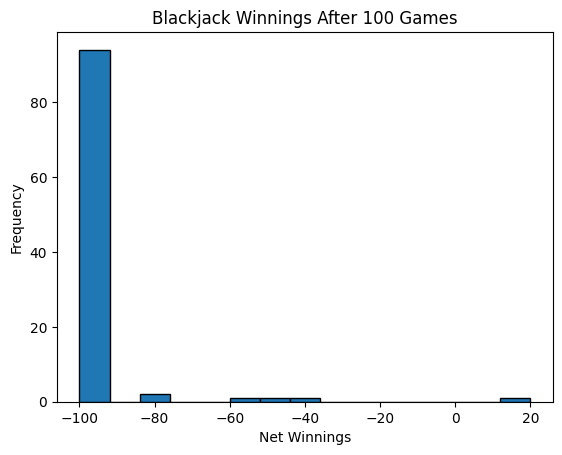

In [22]:
#8


plt.hist(winnings, bins=15, edgecolor="black")

plt.xlabel("Net Winnings")
plt.ylabel("Frequency")
plt.title("Blackjack Winnings After 100 Games")

plt.show()

Threshold: -4 Average winnings per round: -2.84
Threshold: -2 Average winnings per round: -2.99
Threshold: 0 Average winnings per round: -3.89
Threshold: 2 Average winnings per round: -4.46
Threshold: 4 Average winnings per round: -5.13
Best threshold: -4
Highest average: -2.84


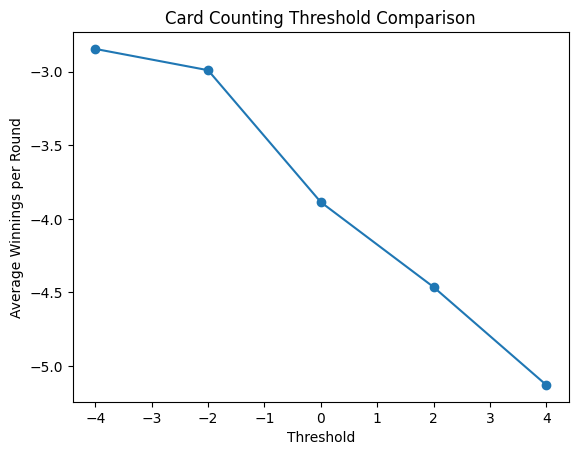

In [23]:
#9
import numpy as np
import matplotlib.pyplot as plt

class CountingPlayer2(CountingPlayer):
    def __init__(self, name, threshold):
        super().__init__(name)
        self.threshold = threshold

    def hit_or_stay(self):
        if self.count < self.threshold:
            return "hit"
        return "stay"


class StrategyGame2(StrategyGame):
    def __init__(self, threshold):
        super().__init__()
        self.counter = CountingPlayer2("Counter", threshold)


thresholds = [-4, -2, 0, 2, 4]
averages = []

for threshold in thresholds:
    winnings = []
    total_rounds = 0

    for i in range(100):
        game = StrategyGame2(threshold)
        rounds = 0

        for j in range(50):
            if game.counter.chips <= 0:
                break

            game.play_round()
            rounds += 1

        winnings.append(game.counter.chips - 100)
        total_rounds += rounds

    average = sum(winnings) / total_rounds
    averages.append(average)

    print("Threshold:", threshold,
          "Average winnings per round:", round(average, 2))

best = thresholds[np.argmax(averages)]

print("Best threshold:", best)
print("Highest average:", round(max(averages), 2))

plt.plot(thresholds, averages, marker="o")
plt.xlabel("Threshold")
plt.ylabel("Average Winnings per Round")
plt.title("Card Counting Threshold Comparison")
plt.show()

Original strategy average: -3.67
New strategy average: -0.91
New strategy performed better.


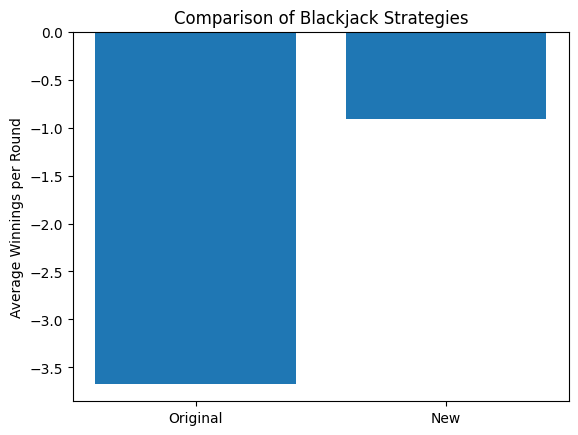

In [24]:
#10
import random
import numpy as np
import matplotlib.pyplot as plt

class NewPlayer(CountingPlayer):
    def hit_or_stay(self):
        if self.hand.get_value() < 17:
            return "hit"
        return "stay"


class NewGame(StrategyGame):
    def __init__(self):
        super().__init__()
        self.counter = NewPlayer("New Player")


old_winnings = []
new_winnings = []
old_rounds = 0
new_rounds = 0

for i in range(100):
    random.seed(i)
    old_game = StrategyGame()

    for j in range(50):
        if old_game.counter.chips <= 0:
            break
        old_game.play_round()
        old_rounds += 1

    old_winnings.append(old_game.counter.chips - 100)

    random.seed(i)
    new_game = NewGame()

    for j in range(50):
        if new_game.counter.chips <= 0:
            break
        new_game.play_round()
        new_rounds += 1

    new_winnings.append(new_game.counter.chips - 100)


old_average = sum(old_winnings) / old_rounds
new_average = sum(new_winnings) / new_rounds

print("Original strategy average:", round(old_average, 2))
print("New strategy average:", round(new_average, 2))

if new_average > old_average:
    print("New strategy performed better.")
elif new_average < old_average:
    print("Original strategy performed better.")
else:
    print("Both strategies performed equally.")

plt.bar(["Original", "New"], [old_average, new_average])
plt.ylabel("Average Winnings per Round")
plt.title("Comparison of Blackjack Strategies")
plt.show()